
Nombre: Ariel Torres Moreno

Matrícula: A01840187


Actividad - Dataset - Notebook

Datos: 'Telco Customer Churn' de Kagle

Descripción de la base de datos y el problema a resolver (traducido de la página de kagle).

Customer churn es un problema fundamental para la industria de las telecomunicaciones. Se define como la pérdida de clientes que se cambian de operador. Si se puede predecir la pérdida de clientes con antelación, por ejemplo, "¿este cliente nos dejará en los próximos X meses?", los operadores pueden aplicar estrategias de marketing dirigidas a estos clientes potenciales para retenerlos y aumentar su base de clientes. En particular, considerando los millones de clientes, incluso reducir la tasa de abandono en un 1% generará un aumento significativo de las ganancias.

Podemos definir el análisis de la pérdida de clientes como el conjunto de estudios analíticos sobre "un cliente", "un producto o servicio" y "la probabilidad de abandono". Nuestro objetivo es detectar esta situación (incluso si el propio cliente no es consciente de ella) antes de que el cliente nos deje (o esté cerca de hacerlo) y, posteriormente, tomar medidas preventivas.

Los datos de pérdida de clientes en el sector de las telecomunicaciones incluyen información sobre una empresa ficticia que proporcionó servicios de telefonía fija e internet a 7043 clientes en California durante el tercer trimestre. ¿Qué clientes se han ido, se han quedado o se han inscrito en sus programas de servicio?

Problema del negocio

Es deseable desarrollar un modelo de aprendizaje automático capaz de predecir qué clientes abandonarán la empresa. Se espera que realice el análisis de datos y la ingeniería de características necesarios antes de desarrollar el modelo.

En este proyecto, se utilizó el conjunto de datos "Telco Customer Churn" de Kaggle. Cada fila representa un cliente y cada columna contiene sus atributos. Este conjunto de datos contiene 21 columnas (variables) y 7043 filas (clientes) con información como ID de cliente, género, servicio telefónico y servicio de internet. 

Análisis de los datos para identificar las variables independientes y la variable dependiente.


- X respresenta las variables independientes - las variables que son usadas para la predicción

customerID - valor único que identifica al cliente.

gender - indica si el cliente es hombre o mujer.

SeniorCitizen - indica si el cliente es adulto mayor (1, 0).

Partner - indica si el cliente tiene pareja (Sí, No).

Dependents - indica si el cliente tiene personas a su cargo (Sí, No). Una persona dependiente es aquella que depende de otra como principal fuente de ingresos.

tenure -número de meses que el cliente ha permanecido en la empresa.

PhoneService - indica si el cliente dispone de servicio telefónico (Sí, No).

MultipleLines - indica si el cliente dispone de varias líneas (Sí, No, Sin servicio telefónico).

InternetService - proveedor de internet del cliente (DSL, Fibra óptica, No).

OnlineSecurity - indica si el cliente dispone de seguridad en línea (Sí, No, Sin servicio de internet).

OnlineBackup - indica si el cliente dispone de copia de seguridad en línea (Sí, No, Sin servicio de internet).

DeviceProtection - indica si el cliente dispone de protección de dispositivos (Sí, No, Sin servicio de internet).

TechSupport - indica si el cliente dispone de soporte técnico (Sí, No, Sin servicio de internet).

StreamingTV - indica si el cliente dispone de televisión por streaming (Sí, No, Sin servicio de internet).

StreamingMovies - indica si el cliente dispone de películas por streaming (Sí, No, Sin servicio de internet).

Contract - tipo de contrato según su duración. (Mensual, Anual, Bienal)

PaperlessBilling - facturas emitidas en formato electrónico (Sí, No)

PaymentMethod - método de pago utilizado por el cliente (Cheque electrónico, Cheque por correo, Tarjeta de crédito (automática), Transferencia bancaria (automática))

MonthlyCharges - importe del servicio mensualmente

TotalCharges - cargos acumulados por el servicio durante el período de suscripción (duración).


- y es la variable dependiente - variable que estamos tratando de predecir o estimar

Churn – variable de salida, variable a predecir.

In [1]:
# Importamos las librerías necesarias

# Librerías para la manipulación de datos
import pandas as pd
import numpy as np

# Librerías para la visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para split de datos y modelado
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier


In [2]:
'''
Paso 1: Carga y describe el dataset:

Importa los datos en un notebook.
Describe su estructura (número de registros, variables, tipos y significado).

'''

telco = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(telco.info())

print("Podemos observar de la tabla que arroja telco.info() que tenemos 7043 registros, 21 variables, de las cuales 18 son de tipo object,\n"             
"2 variables son de tipo int64 y una variable es de tipo float64. La variable objetivo es Churn, la cual indica si un cliente ha cancelado\n"
"su servicio (Yes) o no (No). El significado de las variables se dió en el Markdown anterior.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Mostramos las estadísticas descriptivas de las variables numéricas:

       SeniorCitizen   tenure  MonthlyCharges
count        7043.00  7043.00         7043.00
mean            0.16    32.37           64.76
std             0.37    24.56           30.09
min             0.00     0.00           18.25
25%             0.00     9.00           35.50
50%             0.00    29.00           70.35
75%             0.00    55.00           89.85
max             1.00    72.00          118.75


Mostramos las estadísticas descriptivas de las variables categóricas:

                 count unique               top  freq
customerID        7043   7043        7590-VHVEG     1
gender            7043      2              Male  3555
Partner           7043      2                No  3641
Dependents        7043      2                No  4933
PhoneService      7043      2               Yes  6361
MultipleLines     7043      3                No  3390
InternetService   7043      3       Fiber optic  3096
OnlineSecuri

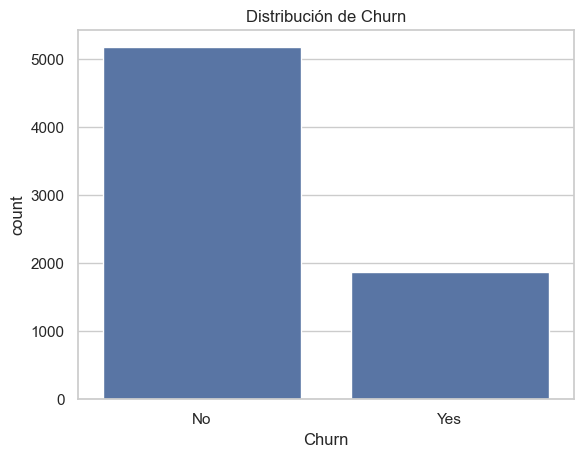



Distribución de las variables numéricas y su relación con churn:



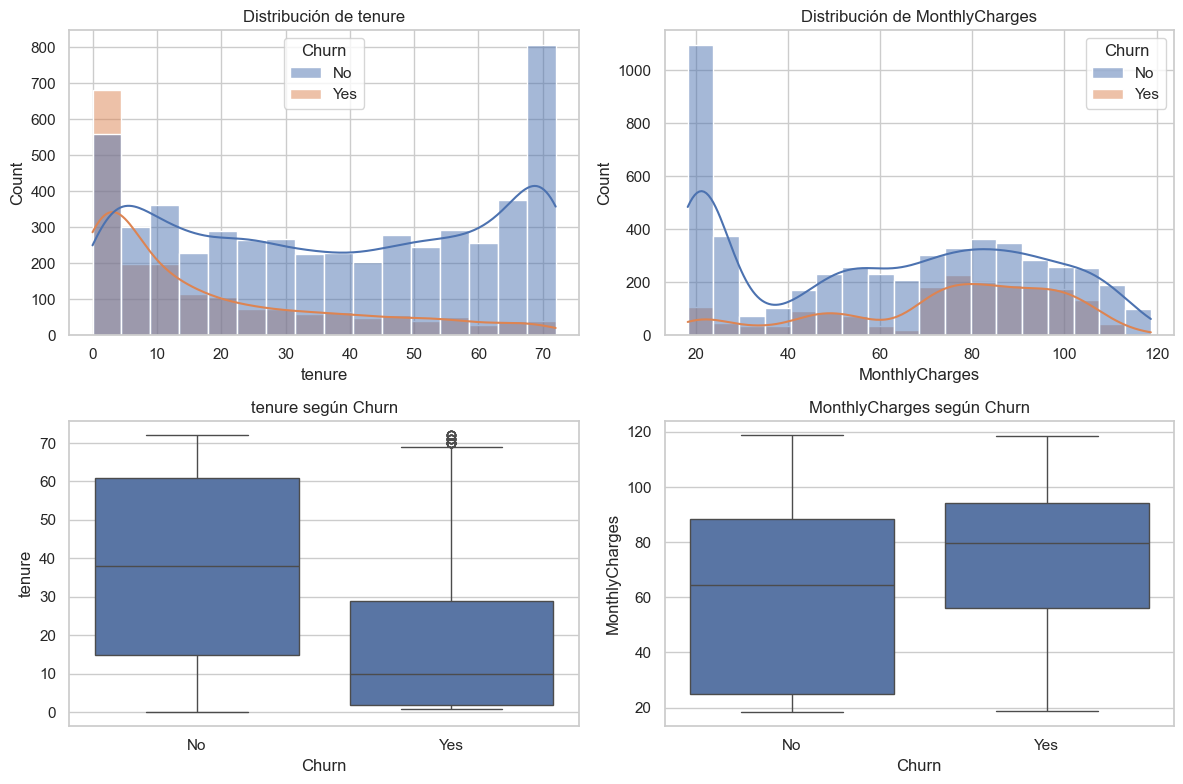



Distribución de las variables categóricas y su relación con churn:



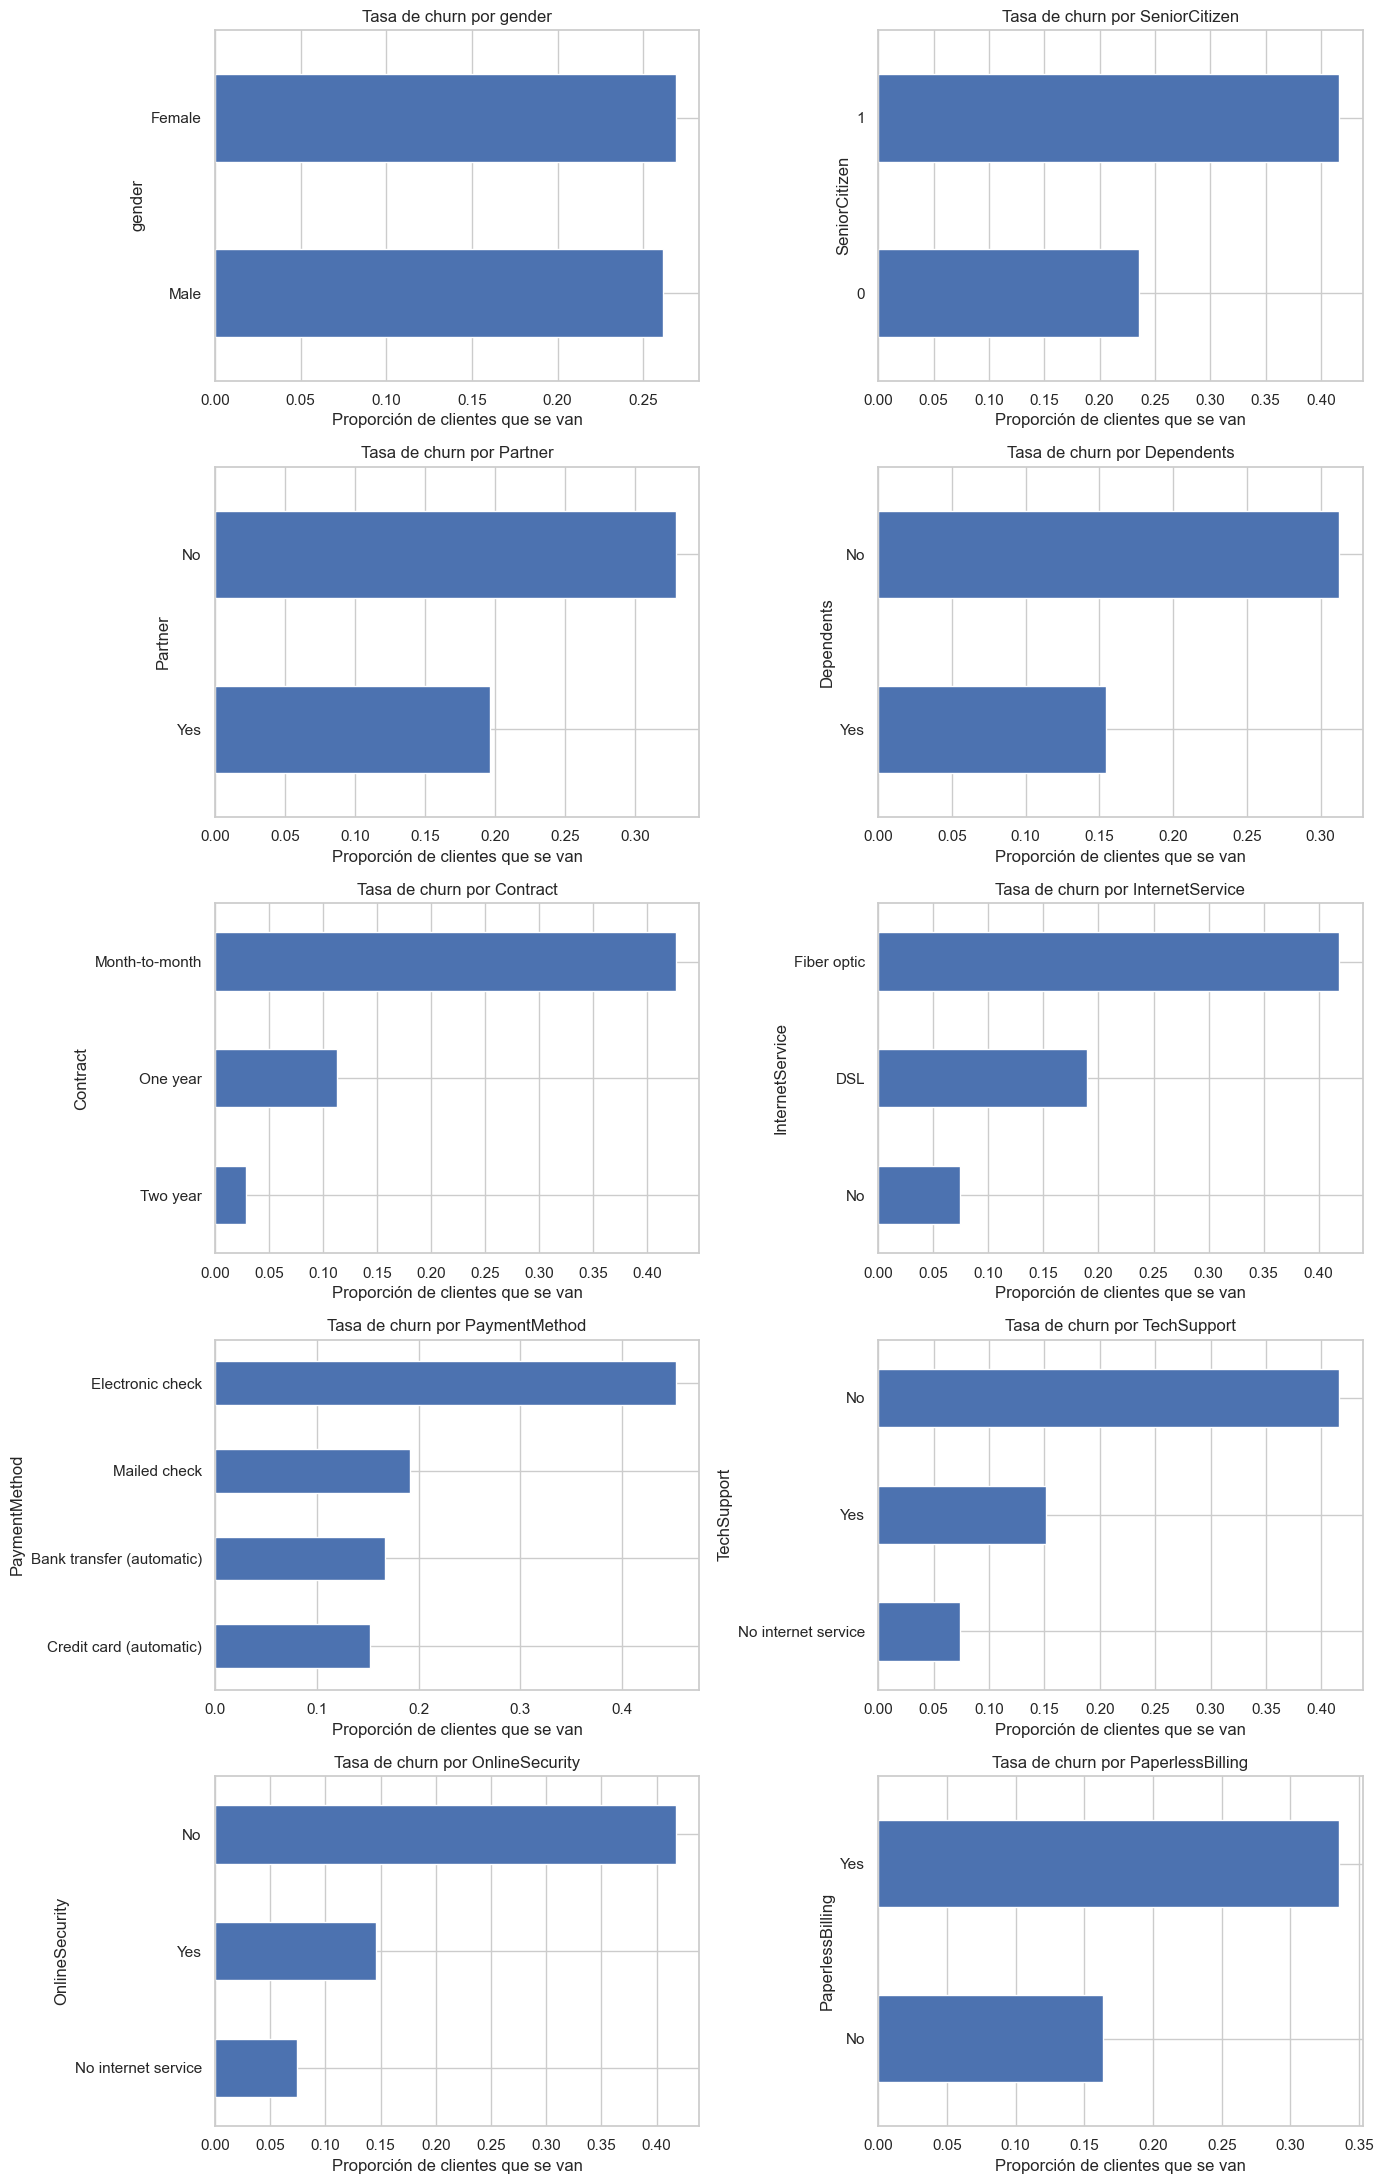



Matriz de correlación entre las variables numéricas:



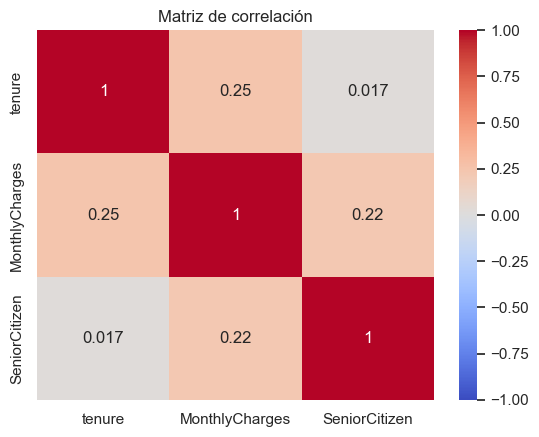

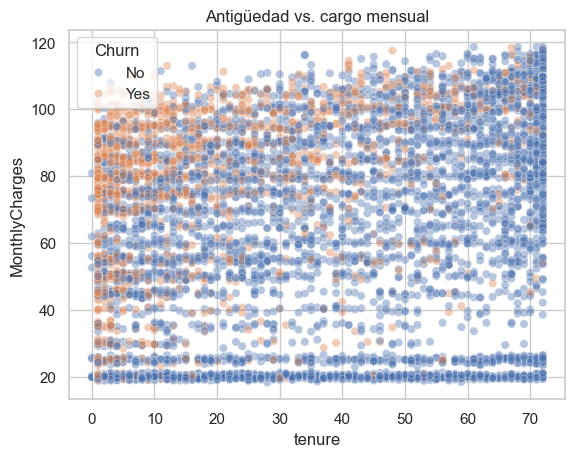

In [3]:
'''
Paso 2: Realiza un análisis exploratorio (EDA):

Genera estadísticas descriptivas y visualizaciones que te permitan entender la distribución de las variables y las relaciones entre ellas.
'''

sns.set_theme(style="whitegrid") # matplotlib hace las gráficas, seaborn las simplifica y les da mejor aspecto, y set_theme define un estilo con fondo cuadriculado.

print("Mostramos las estadísticas descriptivas de las variables numéricas:\n")
print(telco.describe().round(2))
print("\n")
print("Mostramos las estadísticas descriptivas de las variables categóricas:\n")
print(telco.select_dtypes(exclude="number").describe().T)
print("\n")
print("Distribución de la variable objetivo Churn:\n")
print(telco["Churn"].value_counts(normalize=True).round(3))
print("\n")
print("Distribución de la variable objetivo Churn:\n")

sns.countplot(data=telco, x="Churn")
plt.title("Distribución de Churn")
plt.show()
print("\n")
print("Distribución de las variables numéricas y su relación con churn:\n")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, col in enumerate(["tenure", "MonthlyCharges"]):
    sns.histplot(data=telco, x=col, hue="Churn", kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Distribución de {col}")
    sns.boxplot(data=telco, x="Churn", y=col, ax=axes[1, i])
    axes[1, i].set_title(f"{col} según Churn")

plt.tight_layout()
plt.show()
print("\n")
print("Distribución de las variables categóricas y su relación con churn:\n")

categoricas = ["gender", "SeniorCitizen", "Partner", "Dependents",
               "Contract", "InternetService", "PaymentMethod", "TechSupport",
               "OnlineSecurity", "PaperlessBilling"]

fig, axes = plt.subplots(5, 2, figsize=(14, 22))

for ax, col in zip(axes.flatten(), categoricas):
    tasa = (telco.groupby(col)["Churn"]
            .apply(lambda s: (s == "Yes").mean())
            .sort_values())
    tasa.plot(kind="barh", ax=ax)
    ax.set_title(f"Tasa de churn por {col}")
    ax.set_xlabel("Proporción de clientes que se van")

plt.tight_layout()
plt.show()
print("\n")
print("Matriz de correlación entre las variables numéricas:\n")
sns.heatmap(telco[["tenure", "MonthlyCharges", "SeniorCitizen"]].corr(),
            annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()

sns.scatterplot(data=telco, x="tenure", y="MonthlyCharges",
                hue="Churn", alpha=0.4)
plt.title("Antigüedad vs. cargo mensual")
plt.show()

### Hallazgos del análisis exploratorio (EDA)

**1. Variable objetivo desbalanceada**
El 73.5% de los clientes permanece (`No`) y el 26.5% abandona la empresa (`Yes`); es decir, aproximadamente uno de cada cuatro clientes se va. Este desbalance es relevante para la evaluación: un modelo que siempre predijera "No" acertaría el 73.5% de las veces sin aportar nada, por lo que la exactitud (accuracy) por sí sola no sería suficiente para juzgar el modelo.

**2. Distribución de las variables numéricas**
- `tenure` (meses como cliente) va de 0 a 72, con media de 32.4 y mediana de 29. El histograma muestra dos concentraciones: muchos clientes nuevos y otro grupo grande de clientes muy antiguos, cercanos a los 72 meses.
- `MonthlyCharges` (cargo mensual) va de 18.25 a 118.75 USD, con media de 64.76 y mediana de 70.35. Hay un pico en los cargos bajos (alrededor de 20 USD), que corresponde a clientes con servicios básicos, y el resto se reparte en cargos medios y altos.
- `SeniorCitizen` es una variable 0/1: el 16% de los clientes son adultos mayores.

**3. Relación de las variables numéricas con Churn**
- Los clientes que se van llevan mucho menos tiempo en la empresa: mediana de 10 meses frente a 38 de los que se quedan. El abandono se concentra en los primeros meses de la relación. Todo esto puede verse en los boxplot.
- Los clientes que se van pagan más: mediana de 79.65 USD frente a 64.43 USD de los que se quedan.
- Todo lo anterior puede inferirse de los boxplot.
- Lo siguiente se infiere de los histogramas.
- El color azul corresponde a los clientes que permanecen y el naranja a los que abandonan (las zonas moradas son donde ambos se superponen). Las líneas son curvas suavizadas que muestran la forma de la distribución de cada grupo.
- En `tenure`, la curva naranja tiene su pico en los primeros meses y cae rápidamente: en el primer tramo hay más clientes que se van que clientes que se quedan. La curva azul alcanza su punto más alto cerca de los 72 meses, donde casi no hay abandonos.
- En `MonthlyCharges`, el pico de cargos bajos (~20 USD) está formado casi por completo por clientes que permanecen, mientras que los que abandonan se concentran entre 70 y 100 USD.

**4. Relación de las variables categóricas con Churn (tasa de abandono por grupo)**
- **Tipo de contrato:** es la variable con mayor diferencia. Mes a mes 42.7%, anual 11.3% y bianual 2.8%. Los contratos largos se asocian fuertemente con la permanencia.
- **Servicio de internet:** fibra óptica 41.9%, DSL 19.0% y sin internet 7.4%.
- **Método de pago:** cheque electrónico 45.3%, frente a 15%–19% del resto de los métodos.
- **Soporte técnico y seguridad en línea:** sin soporte técnico 41.6% frente a 15.2% con soporte; sin seguridad en línea 41.8% frente a 14.6% con ella.
- **Perfil del cliente:** los adultos mayores abandonan más (41.7% frente a 23.6%), igual que quienes no tienen pareja (33.0% frente a 19.7%) o no tienen dependientes (31.3% frente a 15.5%).
- **Factura electrónica:** 33.6% con factura electrónica frente a 16.3% sin ella.
- **Género:** prácticamente no hay diferencia (26.9% mujeres frente a 26.2% hombres), por lo que esta variable probablemente aporte poco a la predicción.

**5. Relaciones entre variables numéricas**
Las correlaciones entre `tenure`, `MonthlyCharges` y `SeniorCitizen` son débiles (la mayor es 0.25, entre `tenure` y `MonthlyCharges`), por lo que no hay variables redundantes entre ellas. En el diagrama de dispersión, los clientes que abandonan se concentran en la zona de poca antigüedad y cargo mensual alto.

**Conclusión del EDA**
El perfil de mayor riesgo de abandono es un cliente con contrato mes a mes, poca antigüedad, cargo mensual alto, internet por fibra óptica, pago con cheque electrónico y sin servicios de soporte o seguridad. Estas variables son buenas candidatas para el modelo, mientras que `gender` muestra poca relación con el abandono. Es importante aclarar que estas son asociaciones observadas en los datos, no relaciones de causa y efecto.